<a href="https://colab.research.google.com/github/Jiny6771/Connect-AI/blob/main/%E1%84%90%E1%85%A1%E1%84%8B%E1%85%B5%E1%84%90%E1%85%A1%E1%84%82%E1%85%B5%E1%86%A8_1%E1%84%80%E1%85%A1%E1%86%BC_ipynb%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 타이타닉 — 누가 살아남았을까
### 강의에서 말한 그 예제를 직접 손으로

**나만의 인공지능 — 로컬AI의 정석** · 1강 실습 교재

---

강의에서 이렇게 말했습니다.

> "내가 10명 사람의 정보를 줄 거야. 이 사람은 남성이고, 몇 살이고… 근데 이 사람은 살았어.
> 그 다음 사람은… 생존을 하지 못했어. 이 데이터를 모두 줄 테니까
> **네가 잘 학습해서 예측할 수 있는 인공지능 모델을 만들어 봐.**"

오늘 그 말을 그대로 실행합니다. 세 걸음입니다.

| | 할 일 | 강의에서 |
|---|---|---|
| **1** | 두뇌를 **만든다** | 케라스 · 시퀀셜 · 도화지 모양 |
| **2** | 두뇌를 **가르친다** | 에포크 500번 · 로스(거리)를 줄인다 |
| **3** | 두뇌를 **열어본다** | w 와 b 가 무엇인지 확인 |

| | |
|---|---|
| 걸리는 시간 | 20분 |
| 드는 돈 | **0원** |
| 설치할 것 | **없습니다** |

---
# 1 · 승객 명단 올리기

1912년 타이타닉에 탔던 승객 **1,309명**의 실제 명단입니다.

아래 셀을 실행하면 **파일 고르기 창**이 뜹니다. `titanic.xls` 를 고르세요.

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras

# 파일이 이미 있으면 그대로 쓰고, 없으면 고르기 창을 띄웁니다
if os.path.exists('titanic.xls'):
    파일 = 'titanic.xls'
else:
    from google.colab import files
    파일 = list(files.upload())[0]

승객 = pd.read_csv(파일) if 파일.endswith('.csv') else pd.read_excel(파일)
print(f'{len(승객)}명의 명단을 읽었습니다')

Saving titanic.xls to titanic.xls
1309명의 명단을 읽었습니다


### 강의에서 말한 그 표

「이 사람은 남성이고, 몇 살이고, 살았어」— 열이 14개나 있지만 오늘은 **다섯 개만** 봅니다.

- **생존** 1 = 살았다, 0 = 죽었다
- **등급** 1 · 2 · 3 = 1등석 · 2등석 · 3등석
- **나이** NaN = 기록이 없음

In [5]:
표 = pd.DataFrame({
    '이름': 승객['name'],
    '성별': 승객['sex'],
    '나이': 승객['age'],
    '등급': 승객['pclass'],
    '운임요금':승객['fare'],
    '동승가족수':승객['sibsp'] + 승객['parch'],
    '생존': 승객['survived'],
    '키':승객['body'],
})

print(f'{len(표)}명 중 {표["생존"].sum()}명이 살았습니다')
표.head(10)                       # 강의처럼, 열 사람만 봅니다

1309명 중 500명이 살았습니다


,이름,성별,나이,등급,운임요금,동승가족수,생존,키
0,"Allen, Miss. Elisabeth Walton",female,29.0000,1,211.3375,0,1,NaN
1,"Allison, Master. Hudson Trevor",male,0.9167,1,151.5500,3,1,NaN
2,"Allison, Miss. Helen Loraine",female,2.0000,1,151.5500,3,0,NaN
3,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,151.5500,3,0,135.0
4,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,151.5500,3,0,NaN
5,"Anderson, Mr. Harry",male,48.0000,1,26.5500,0,1,NaN
6,"Andrews, Miss. Kornelia Theodosia",female,63.0000,1,77.9583,1,1,NaN
7,"Andrews, Mr. Thomas Jr",male,39.0000,1,0.0000,0,0,NaN
8,"Appleton, Mrs. Edward Dale (Charlotte Lamson)",female,53.0000,1,51.4792,2,1,NaN
9,"Artagaveytia, Mr. Ramon",male,71.0000,1,49.5042,0,0,22.0


In [6]:
print(f"승객의 평균 나이: {표['나이'].mean():.2f}살")

승객의 평균 나이: 29.88살


In [7]:
# 한글 폰트(나눔글꼴) 설치 및 설정
!apt-get update -qq
!apt-get install fonts-nanum* -qq

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 설치된 폰트를 matplotlib에 적용
path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
font_name = fm.FontProperties(fname=path, size=10).get_name()
plt.rc('font', family=font_name)
plt.rcParams['axes.unicode_minus'] = False # 마이너스 기호 깨짐 방지

print("한글 폰트 설정이 완료되었습니다. 아래 시각화 셀을 다시 실행해 보세요!")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-nanum.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Selecting previously unselected package fonts-nanum-coding.
Preparing to unpack .../fonts-nanum-coding_2.5-3_all.deb ...
Unpacking fonts-nanum-coding (2.5-3) ...
Selecting previously unselected package fonts-nanum-eco.
Preparing to unpack .../fonts-nanum-eco_1.000-7_all.deb ...
Unpacking fonts-nanum-eco (1.000-7) ...
Selecting previously unselected package fonts-nanum-extra.
Preparing to unpack .../fonts-nanum-extra_20200506-1_all.deb ...
Unpacking fonts-nanum-extra (20200506-1) ...
Setting up fonts-nanum-extra (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Setting up fo

=== 요금 구간별 평균 생존율 ===
      Fare_Bin        생존
0     Q1_Basic  0.283537
1  Q2_Standard  0.262997
2   Q3_Premium  0.388379
3       Q4_VIP  0.593272




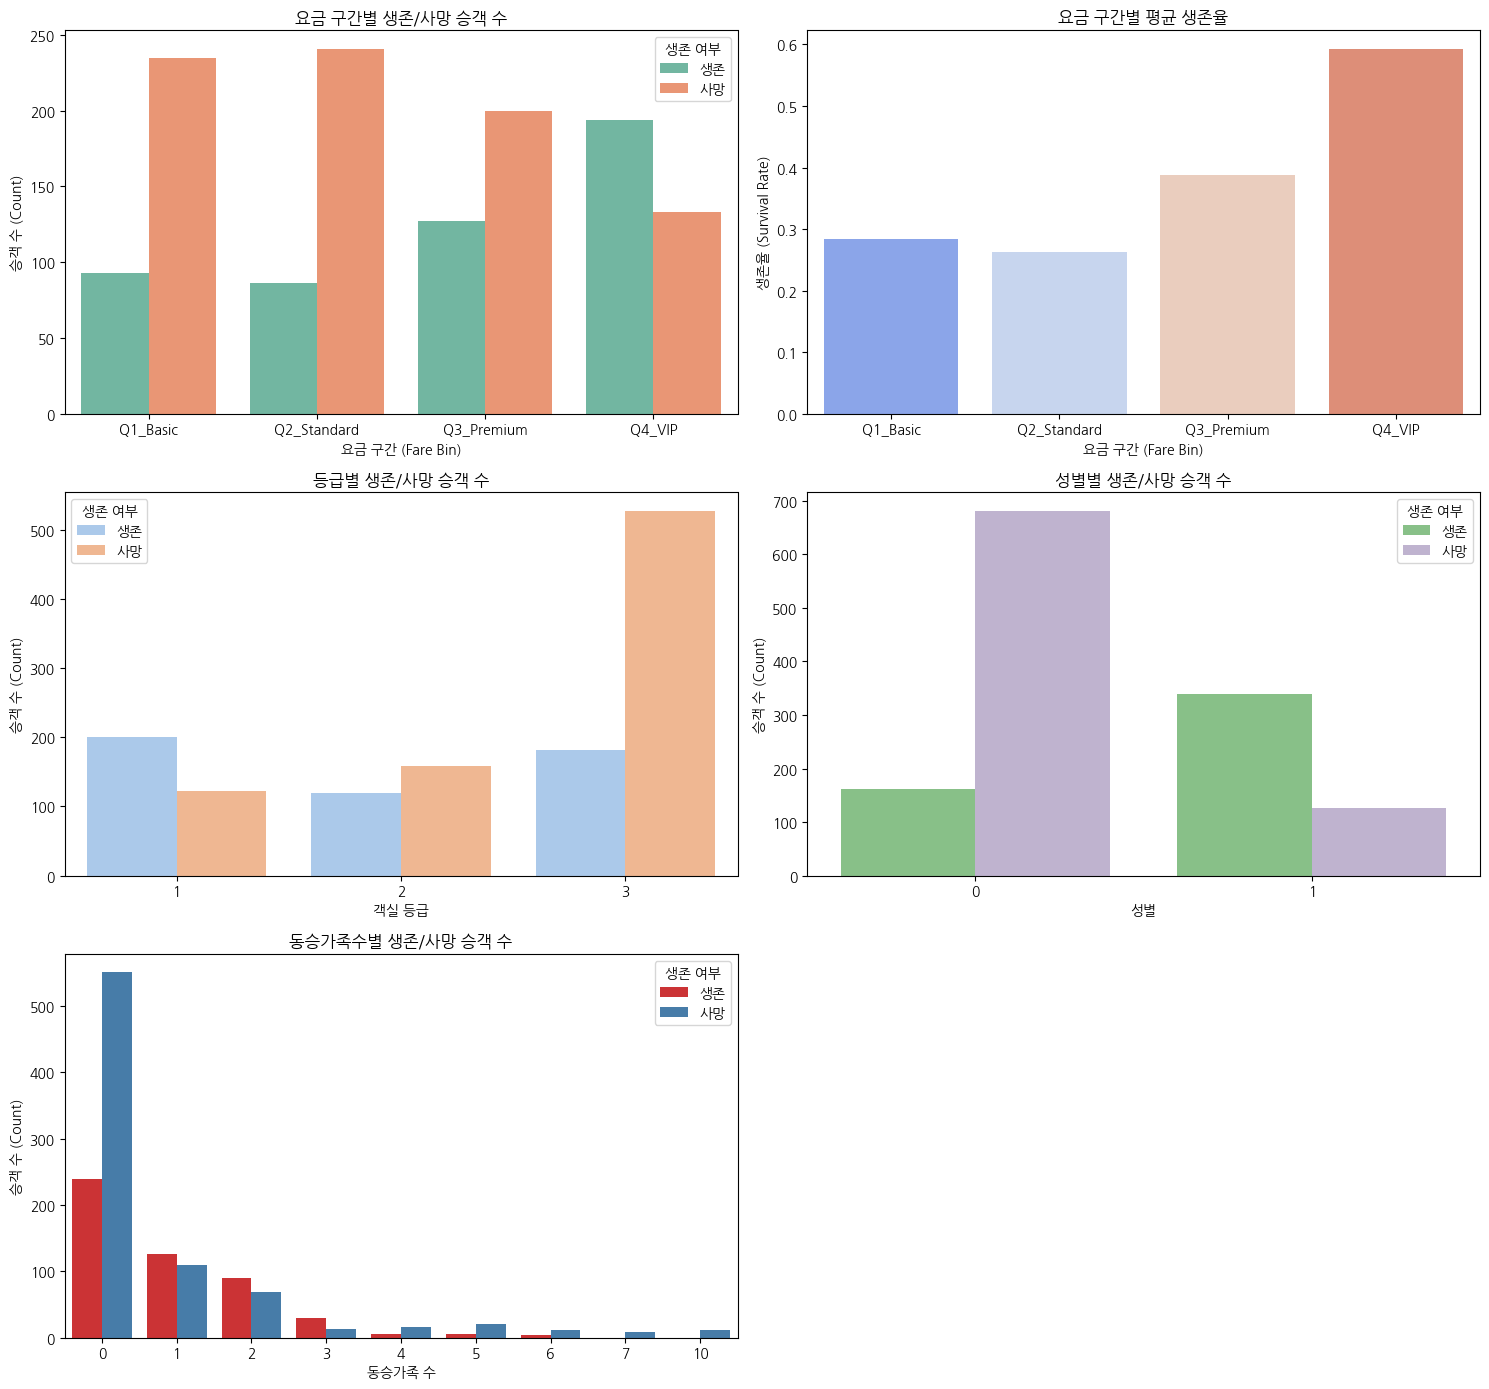

In [10]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 한글 폰트 설정
path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
fm.fontManager.addfont(path)
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

# 1. 가족 규모(Family_Size) 계산: 동승자 수(sibsp + parch) + 본인(1)
표['Family_Size'] = 승객['sibsp'] + 승객['parch'] + 1

# 결측값 처리 (운임 요금 결측치 1건 발생 대비 최빈값/중앙값 대체)
요금_결측치_처리 = 표['운임요금'].median()
표['운임요금'] = 표['운임요금'].fillna(요금_결측치_처리)

# 2. 1인당 실질 요금(Per_Person_Fare) 산출
표['Per_Person_Fare'] = 표['운임요금'] / 표['Family_Size']

# 3. Quantile Binning (4개 구간)
labels = ['Q1_Basic', 'Q2_Standard', 'Q3_Premium', 'Q4_VIP']
표['Fare_Bin'] = pd.qcut(표['Per_Person_Fare'], q=4, labels=labels)

# 구간별 평균 생존율 그룹화 출력
생존율_그룹 = 표.groupby('Fare_Bin', observed=False)['생존'].mean().reset_index()
print("=== 요금 구간별 평균 생존율 ===")
print(생존율_그룹)
print("\n")

# 시각화 가독성을 위해 생존 여부를 한글로 임시 매핑한 컬럼 생성
표['생존_라벨'] = 표['생존'].map({0: '사망', 1: '생존'})

# 시각화 (3x2 구조로 요금 구간, 등급, 성별 및 동승가족수에 따른 분석 그래프 제공)
plt.figure(figsize=(15, 14))

# 1) 요금 구간별 생존/사망 승객 수
plt.subplot(3, 2, 1)
sns.countplot(x='Fare_Bin', hue='생존_라벨', data=표, palette='Set2')
plt.title('요금 구간별 생존/사망 승객 수')
plt.xlabel('요금 구간 (Fare Bin)')
plt.ylabel('승객 수 (Count)')
plt.legend(title='생존 여부')

# 2) 요금 구간별 평균 생존율
plt.subplot(3, 2, 2)
sns.barplot(x='Fare_Bin', y='생존', data=표, errorbar=None, palette='coolwarm', hue='Fare_Bin', legend=False)
plt.title('요금 구간별 평균 생존율')
plt.xlabel('요금 구간 (Fare Bin)')
plt.ylabel('생존율 (Survival Rate)')

# 3) 등급별 생존자 수
plt.subplot(3, 2, 3)
sns.countplot(x='등급', hue='생존_라벨', data=표, palette='pastel')
plt.title('등급별 생존/사망 승객 수')
plt.xlabel('객실 등급')
plt.ylabel('승객 수 (Count)')
plt.legend(title='생존 여부')

# 4) 성별별 생존자 수
plt.subplot(3, 2, 4)
sns.countplot(x='성별', hue='생존_라벨', data=표, palette='Accent')
plt.title('성별별 생존/사망 승객 수')
plt.xlabel('성별')
plt.ylabel('승객 수 (Count)')
plt.legend(title='생존 여부')

# 5) 동승가족수별 생존자 수
plt.subplot(3, 2, 5)
sns.countplot(x='동승가족수', hue='생존_라벨', data=표, palette='Set1')
plt.title('동승가족수별 생존/사망 승객 수')
plt.xlabel('동승가족 수')
plt.ylabel('승객 수 (Count)')
plt.legend(title='생존 여부')

plt.tight_layout()
plt.show()

---
# 2 · 글자를 숫자로

강의에서 사진은 컴퓨터 안에서 **0~255 숫자**라고 했습니다. 글자도 마찬가지입니다.
두뇌에는 숫자만 들어갑니다. 그래서 두 가지를 손봅니다.

| 열 | 지금 | 바꾼 뒤 |
|---|---|---|
| 성별 | female / male | **1 / 0** |
| 나이 | 263명은 기록이 없음 (NaN) | 모르면 **28살** (가운데 나이) |
| 등급 | 1 · 2 · 3 | 이미 숫자. 그대로 |

In [9]:
표['성별'] = 표['성별'].map({'female': 1, 'male': 0})     # 여성 1, 남성 0
표['나이'] = 표['나이'].fillna(28)                          # 나이 모르면 28살

표.head(10)

,이름,성별,나이,등급,운임요금,동승가족수,생존,키,Family_Size,Per_Person_Fare,Fare_Bin,생존_라벨
0,"Allen, Miss. Elisabeth Walton",1,29.0000,1,211.3375,0,1,NaN,1,211.337500,Q4_VIP,생존
1,"Allison, Master. Hudson Trevor",0,0.9167,1,151.5500,3,1,NaN,4,37.887500,Q4_VIP,생존
2,"Allison, Miss. Helen Loraine",1,2.0000,1,151.5500,3,0,NaN,4,37.887500,Q4_VIP,사망
3,"Allison, Mr. Hudson Joshua Creighton",0,30.0000,1,151.5500,3,0,135.0,4,37.887500,Q4_VIP,사망
4,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",1,25.0000,1,151.5500,3,0,NaN,4,37.887500,Q4_VIP,사망
5,"Anderson, Mr. Harry",0,48.0000,1,26.5500,0,1,NaN,1,26.550000,Q4_VIP,생존
6,"Andrews, Miss. Kornelia Theodosia",1,63.0000,1,77.9583,1,1,NaN,2,38.979150,Q4_VIP,생존
7,"Andrews, Mr. Thomas Jr",0,39.0000,1,0.0000,0,0,NaN,1,0.000000,Q1_Basic,사망
8,"Appleton, Mrs. Edward Dale (Charlotte Lamson)",1,53.0000,1,51.4792,2,1,NaN,3,17.159733,Q3_Premium,생존
9,"Artagaveytia, Mr. Ramon",0,71.0000,1,49.5042,0,0,22.0,1,49.504200,Q4_VIP,사망


---
# 3 · 둘로 나누기

명단을 섞은 뒤 둘로 나눕니다.

```
  가르칠 명단  891명  →  정답(생존)을 보여 주고 배우게 한다
  시험 명단    418명  →  정답을 감추고, 배운 걸로 맞혀 보게 한다
```

시험 명단의 정답은 채점할 때까지 따로 감춰 둡니다.

In [11]:
표 = 표.sample(frac=1, random_state=3)     # 카드 섞듯 순서를 섞습니다 (3은 '매번 똑같이 섞어라'는 뜻)

가르칠명단 = 표[:891]
시험명단   = 표[891:].drop(columns='생존')     # 시험지에서는 정답을 뺍니다
시험정답   = 표[891:]['생존'].values          # 채점용. 두뇌에게는 안 보여 줍니다

print(f'가르칠 명단 {len(가르칠명단)}명 · 시험 명단 {len(시험명단)}명')

가르칠 명단 891명 · 시험 명단 418명


### 입력값과 결괏값

강의에서 「입력값과 결괏값만 주면서, 네가 알아서 함수를 만들어」라고 했습니다.

- **입력값** = 성별 · 나이 · 등급, 숫자 세 개
- **결괏값** = 생존, 1 또는 0

In [12]:
입력 = 가르칠명단[['성별', '나이', '운임요금', '등급', '동승가족수']].values     # 891명 × 숫자 5개
정답 = 가르칠명단['생존'].values                       # 891명 × 살았나(1) 죽었나(0)

print('첫 사람  입력:', 입력[0], ' →  정답:', 정답[0])

첫 사람  입력: [ 0.     28.     19.9667  3.      1.    ]  →  정답: 0


---
# 4 · 두뇌 만들기

강의에서 본 함수입니다.

```
   y = w·x + b
```

지금은 x 가 셋(성별 · 나이 · 등급)이라 w 도 셋입니다. 그리고 끝에 한 가지가 붙습니다.

```
   성별 ──× w₁ ──┐
   나이 ──× w₂ ──┼──▶ ( + b ) ──▶ [ 0~1 로 누르기 ] ──▶ 살 확률
   등급 ──× w₃ ──┘
```

「0~1 로 누르기」는 결과가 몇이 나오든 **0과 1 사이의 확률**로 눌러 주는 장치입니다.
코드에서는 `sigmoid` 라고 씁니다. 이름만 알아 두세요.

| 부품 | 하는 일 |
|---|---|
| `Input(shape=(3,))` | 숫자 세 개가 들어옵니다 — 강의의 「도화지 모양」 |
| `Dense(1, activation='sigmoid')` | 계산 칸 하나. 곱하고 더한 뒤 0~1 로 누릅니다 |
| `loss='mse'` | 얼마나 틀렸는지 재는 자 — 강의의 「로스 = 거리」 |
| `optimizer` | 틀린 만큼 w 와 b 를 고치는 방법 |

w 와 b 는 지금 **아무 숫자**나 들어 있습니다. 가르치면서 찾아갈 겁니다.

In [31]:
생존두뇌 = keras.Sequential([
    keras.Input(shape=(5,)),                        # 성별, 나이, 운임요금, 등급, 동승가족수
    keras.layers.Dense(8, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid'),    # 계산 칸 하나 → 살 확률
])
생존두뇌.compile(loss='mse', optimizer=keras.optimizers.Adam(0.003))

w, b = 생존두뇌.layers[0].get_weights()
print('가르치기 전  w :', w.flatten().round(3), '  b :', b.round(3))
print('아직 아무렇게나 들어 있는 숫자입니다.')

가르치기 전  w : [-0.467  0.313 -0.189 -0.032 -0.576  0.647  0.413  0.595  0.636 -0.321
 -0.18  -0.053 -0.672  0.217  0.451 -0.617  0.561  0.01  -0.046  0.32
 -0.103 -0.62  -0.443  0.053  0.487  0.544  0.108 -0.012  0.244 -0.242
  0.112 -0.136 -0.289 -0.234  0.118 -0.375 -0.441 -0.508  0.146 -0.389]   b : [0. 0. 0. 0. 0. 0. 0. 0.]
아직 아무렇게나 들어 있는 숫자입니다.


---
# 5 · 가르치기

강의에서 「에포크 500번」이라고 했습니다. 한 번에 500번을 시키는 대신
**100번마다 멈춰서** w 와 b 가 어떻게 바뀌는지 들여다봅니다. 맨 윗줄 0번은 가르치기 전입니다.
강의에서 「학습 중간중간 어떤 w 와 b 를 찾았는지 볼 수 있다」고 한 그 장면입니다.

In [36]:
틀린정도_기록 = []

for 번 in range(0, 3001, 100):
    if 번 > 0:
        학습 = 생존두뇌.fit(입력, 정답, epochs=100, verbose=0)   # 100번 가르치고
        틀린정도_기록 += 학습.history['loss']

    w, b = 생존두뇌.layers[0].get_weights()                    # 열어봅니다
    틀린정도 = 생존두뇌.evaluate(입력, 정답, verbose=0)         # 지금 얼마나 틀리나

    # 층이 깊어져 w의 개수가 5개를 넘으면 전부 출력하기 어려우므로 나누어 처리합니다
    if len(w.flatten()) == 5:
        w성별, w나이, w요금, w등급, w가족 = w.flatten()              # w 다섯 개를 풀어 놓습니다
        print(f'{번:3d}번 →  성별×{w성별:.2f}  나이×{w나이:.3f}  요금×{w요금:.3f}  등급×{w등급:.2f}  가족×{w가족:.2f}  + {b[0]:.2f}    틀린 정도 {틀린정도:.3f}')
    else:
        print(f'{번:3d}번 →  (은닉층 추가로 첫 번째 층 w가 {len(w.flatten())}개로 늘어났습니다)    틀린 정도 {틀린정도:.3f}')

  0번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.133
100번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.136
200번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.133
300번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.134
400번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.132
500번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.134
600번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.132
700번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.132
800번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.133
900번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.133
1000번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.132
1100번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.132
1200번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.132
1300번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.132
1400번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.132
1500번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.132
1600번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.132
1700번 →  (은닉층 추가로 첫 번째 층 w가 40개로 늘어났습니다)    틀린 정도 0.132
18

### 거리가 줄어드는 모습

강의에서 「선을 그려 보고, 거리가 머네, 다시 그려 보고, 줄어들었네」라고 했습니다.
그걸 500번 반복한 기록입니다.

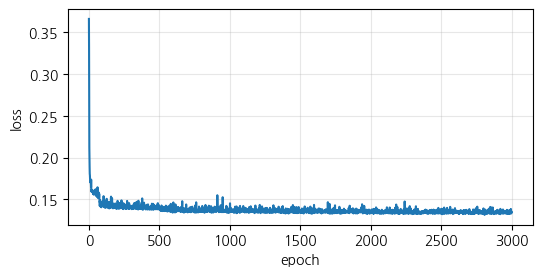

In [34]:
plt.figure(figsize=(6, 2.8))
plt.plot(틀린정도_기록)
plt.xlabel('epoch'); plt.ylabel('loss'); plt.grid(alpha=.3)
plt.show()

---
# 6 · 열어보기 — 기계가 찾아낸 함수

공식을 알려 준 적이 없습니다. 891명의 명단만 보고 두뇌가 **스스로** 정한 w 와 b 입니다.

In [37]:
w, b = 생존두뇌.layers[0].get_weights()

print('두뇌가 찾아낸 함수')
if len(w.flatten()) == 5:
    w성별, w나이, w요금, w등급, w가족 = w.flatten()
    print(f'살 확률 = 누르기( {w성별:.2f}×성별  {w나이:.3f}×나이  {w요금:.3f}×요금  {w등급:.2f}×등급  {w가족:.2f}×가족  + {b[0]:.2f} )')
else:
    w1, b1 = 생존두뇌.layers[0].get_weights()
    w2, b2 = 생존두뇌.layers[1].get_weights()
    변수명 = ['성별', '나이', '요금', '등급', '가족']

    print("은닉층(8개 노드)이 추가되어 공식이 2단계로 깊어졌습니다!\n")

    print("[ 1단계 : 8개의 숨겨진 노드 값 계산 ]")
    for i in range(8):
        식 = " + ".join([f"{w1[j, i]:.2f}×{변수명[j]}" for j in range(5)])
        print(f" 노드{i+1} = ReLU( {식} + {b1[i]:.2f} )")

    print("\n[ 2단계 : 최종 생존 확률 계산 ]")
    최종식 = " + ".join([f"{w2[i, 0]:.2f}×노드{i+1}" for i in range(8)])
    print(f" 살 확률 = 누르기( {최종식} + {b2[0]:.2f} )")

두뇌가 찾아낸 함수
은닉층(8개 노드)이 추가되어 공식이 2단계로 깊어졌습니다!

[ 1단계 : 8개의 숨겨진 노드 값 계산 ]
 노드1 = ReLU( -8.26×성별 + 0.21×나이 + 0.00×요금 + 3.45×등급 + 1.31×가족 + -0.91 )
 노드2 = ReLU( -5.44×성별 + -0.56×나이 + -0.00×요금 + 0.34×등급 + -0.58×가족 + 7.82 )
 노드3 = ReLU( -0.19×성별 + -0.18×나이 + -0.05×요금 + 0.11×등급 + 0.12×가족 + 0.00 )
 노드4 = ReLU( 5.21×성별 + -0.08×나이 + 0.03×요금 + -3.03×등급 + 0.56×가족 + 4.86 )
 노드5 = ReLU( -0.58×성별 + -0.67×나이 + -0.10×요금 + 0.24×등급 + -0.44×가족 + 0.00 )
 노드6 = ReLU( 4.37×성별 + 0.37×나이 + -0.07×요금 + -1.83×등급 + 0.90×가족 + 2.69 )
 노드7 = ReLU( -3.98×성별 + -0.07×나이 + -0.16×요금 + 3.22×등급 + -0.50×가족 + -2.47 )
 노드8 = ReLU( 0.64×성별 + -0.83×나이 + 0.01×요금 + -0.11×등급 + -0.40×가족 + 0.37 )

[ 2단계 : 최종 생존 확률 계산 ]
 살 확률 = 누르기( -0.39×노드1 + 0.91×노드2 + -0.81×노드3 + 0.22×노드4 + -0.08×노드5 + 0.22×노드6 + 0.49×노드7 + 1.10×노드8 + 0.11 )


숫자 앞의 부호를 보세요.

| | 부호 | 뜻 |
|---|---|---|
| 성별 | **플러스** | 여성(1)일수록 살 확률이 올라간다 |
| 나이 | **마이너스** | 나이가 많을수록 살 확률이 내려간다 |
| 등급 | **마이너스** | 3등석으로 갈수록 살 확률이 내려간다 |

1912년 타이타닉의 구조 원칙은 **「여성과 아이 먼저」** 였습니다. 그리고 구명보트는 1등석 근처에 있었습니다.

두뇌에게 이 이야기를 해 준 사람은 아무도 없습니다. 숫자 891줄만 보고 찾아낸 것입니다.
강의에서 말한 **「사람이 아니라 기계가 함수를 만든다」** 가 바로 이것입니다.

---
# 7 · 시험 보기

시험 명단 418명에게 살 확률을 물어봅니다. 0.5 를 넘으면 「산다」로 적고, 감춰 둔 정답으로 채점합니다.

In [44]:
시험입력 = 시험명단[['성별', '나이', '운임요금', '등급', '동승가족수']].values

# 생존두뇌.predict() 안에는 우리가 18번 셀에서 보았던 '40개의 가중치'와 '2단계 공식'이 이미 탑재되어 있습니다.
# 따라서 우리가 직접 수식을 적어줄 필요 없이 predict()만 호출하면, 알아서 그 함수를 적용해 계산해 줍니다!
살확률   = 생존두뇌.predict(시험입력, verbose=0).flatten()   # 418명의 살 확률
예측     = (살확률 >= 0.5).astype(int)                      # 0.5 넘으면 1(산다), 아니면 0

시험명단['살 확률(%)'] = (살확률 * 100).round().astype(int)   # 시험 명단에 두 열을 덧붙입니다
시험명단['예측'] = 예측
시험명단.head(10)

,이름,성별,나이,등급,운임요금,동승가족수,키,Family_Size,Per_Person_Fare,Fare_Bin,생존_라벨,살 확률(%),예측
1041,"Murdlin, Mr. Joseph",0,28.0,3,8.0500,0,NaN,1,8.0500,Q2_Standard,사망,9,0
1074,"O'Connor, Mr. Patrick",0,28.0,3,7.7500,0,NaN,1,7.7500,Q2_Standard,사망,9,0
812,"Fox, Mr. Patrick",0,28.0,3,7.7500,0,NaN,1,7.7500,Q2_Standard,사망,9,0
905,"Jonsson, Mr. Carl",0,32.0,3,7.8542,0,NaN,1,7.8542,Q2_Standard,생존,8,0
24,"Bird, Miss. Ellen",1,29.0,1,221.7792,0,NaN,1,221.7792,Q4_VIP,생존,93,1
298,"Tucker, Mr. Gilbert Milligan Jr",0,31.0,1,28.5375,0,NaN,1,28.5375,Q4_VIP,생존,25,0
556,"Sharp, Mr. Percival James R",0,27.0,2,26.0000,0,NaN,1,26.0000,Q4_VIP,사망,5,0
575,"Turpin, Mrs. William John Robert (Dorothy Ann ...",1,27.0,2,21.0000,1,NaN,2,10.5000,Q3_Premium,사망,85,1
18,"Bazzani, Miss. Albina",1,32.0,1,76.2917,0,NaN,1,76.2917,Q4_VIP,생존,98,1
572,"Trout, Mrs. William H (Jessie L)",1,28.0,2,12.6500,0,NaN,1,12.6500,Q3_Premium,생존,88,1


In [46]:
맞힌수 = (예측 == 시험정답).sum()
정확도 = 맞힌수 / len(시험정답) * 100

print("[ 은닉층(8개 노드)이 적용된 두뇌의 채점 결과입니다! ]")
print(f'시험 명단 {len(시험정답)}명 중 {맞힌수}명을 맞혔습니다  →  정확도 {정확도:.1f}%')
print()
print(f'아무것도 안 배우고 「전부 죽었다」고 찍으면  {(시험정답 == 0).mean() * 100:.1f}%')

[ 은닉층(8개 노드)이 적용된 두뇌의 채점 결과입니다! ]
시험 명단 418명 중 334명을 맞혔습니다  →  정확도 79.9%

아무것도 안 배우고 「전부 죽었다」고 찍으면  62.2%


---
# 8 · 내가 탔다면?

강의에서 「사랑해를 넣으면 I love you 가 나온다」고 했습니다.
우리 두뇌는 **성별 · 나이 · 등급을 넣으면 살 확률**이 나옵니다. 아무나 넣어 보세요.

In [27]:
사람들 = [
    ['제이', 0, 38, 70.0, 2, 0],      # 여성, 17살, 1등석 (임의의 요금, 가족수 추가)
    ['잭',   0, 20, 8.0, 3, 0],       # 남성, 20살, 3등석
    ['나',   0, 55, 227.0, 1, 0],      # ← 여기를 내 정보로 바꿔 보세요
]

for 이름, 성별, 나이, 요금, 등급, 가족 in 사람들:
    확률 = 생존두뇌.predict(np.array([[성별, 나이, 요금, 등급, 가족]]), verbose=0)[0][0]
    print(f'{이름:4s}  성별 {성별} · 나이 {나이:2d} · 요금 {요금:4.1f} · 등급 {등급} · 가족 {가족}  →  살 확률 {확률 * 100:.0f}%')

제이    성별 0 · 나이 38 · 요금 70.0 · 등급 2 · 가족 0  →  살 확률 19%
잭     성별 0 · 나이 20 · 요금  8.0 · 등급 3 · 가족 0  →  살 확률 10%
나     성별 0 · 나이 55 · 요금 227.0 · 등급 1 · 가족 0  →  살 확률 36%


### 함수를 그래프로

강의에서 y = wx + b 를 그래프로 그렸습니다. 우리 함수도 그려 봅니다.
나이를 0살부터 80살까지 바꿔 가며 살 확률을 찍은 것입니다.

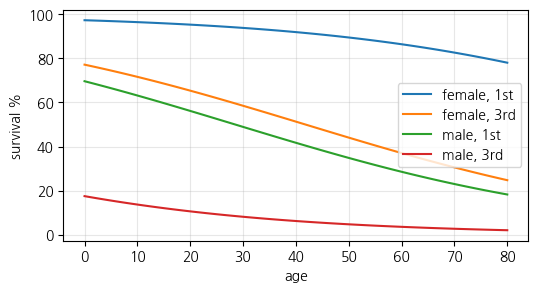

In [28]:
나이들 = np.arange(0, 81)
가족 = 0  # 기본값: 동승가족수 0명

plt.figure(figsize=(6, 3))
# 성별, 등급, 임의의 요금, 라벨
for 성별, 등급, 요금, 라벨 in [(1, 1, 80.0, 'female, 1st'), (1, 3, 15.0, 'female, 3rd'),
                          (0, 1, 80.0, 'male, 1st'),   (0, 3, 15.0, 'male, 3rd')]:
    입력들 = np.array([[성별, 나이, 요금, 등급, 가족] for 나이 in 나이들])
    plt.plot(나이들, 생존두뇌.predict(입력들, verbose=0).flatten() * 100, label=라벨)
plt.xlabel('age'); plt.ylabel('survival %'); plt.legend(); plt.grid(alpha=.3)
plt.show()

---
# 직접 해보기

**① 더 오래 가르쳐 보세요**
5번 셀의 `range(0, 501, 100)` 을 `range(0, 2001, 100)` 으로. 2,000번 가르치면 w 는 어디서 멈출까요?

**② 나이를 빼 보세요**
`['성별', '나이', '등급']` 이 나오는 두 곳에서 `'나이'` 를 지우고, `shape=(3,)` 을 `shape=(2,)` 로.
「내가 탔다면」과 그래프 셀의 숫자도 두 개로 줄여야 합니다. 정확도가 얼마나 떨어질까요?

**③ 요금도 넣어 보세요**
표를 만드는 곳에 `'요금': 승객['fare'],` 한 줄을 넣고, 기록이 없는 한 사람은 `표['요금'] = 표['요금'].fillna(14)` 로 채우세요.
그 다음 ②와 반대로 `'요금'` 을 두 곳에 넣고 `shape=(4,)` 로. 정확도가 오를까요?

**④ 두뇌를 깊게 만들어 보세요**
`Dense(1, ...)` 줄 바로 앞에 `keras.layers.Dense(8, activation='relu'),` 한 줄을 끼워 넣으세요.
층이 두 개가 됩니다. 이게 「딥」러닝의 시작입니다. 단, 층이 둘이면 6번 셀의 `layers[0]` 은 첫 번째 층만 보여 줍니다.

---

## 막히면

| 증상 | 이유와 해결 |
|---|---|
| `NameError` | 위 셀을 건너뛰었습니다. 맨 위부터 순서대로 실행 |
| 파일 고르기 창이 안 뜸 | 왼쪽 📁 아이콘 → 업로드 → titanic.xls 를 올린 뒤 1번 셀 다시 실행 |
| xls 파일을 못 읽는다고 나옴 | titanic.xls 대신 titanic.csv 를 올리세요. 내용은 같습니다 |
| 실행할 때마다 숫자가 조금 다름 | 정상입니다. 가르치기 전 w 와 b 가 매번 무작위라서 그렇습니다 |
| 정확도가 78% 근처에서 안 오름 | 정상입니다. 성별 · 나이 · 등급 셋만으로는 여기가 한계입니다 |

---

## 오늘 확인한 것

| | 강의에서 | 직접 해 본 것 |
|---|---|---|
| 두뇌를 만든다 | 케라스 시퀀셜 · 도화지 모양 | `Input(shape=(3,))` 과 `Dense(1)` |
| 두뇌를 가르친다 | 에포크 500 · 로스를 줄인다 | 100번마다 w 와 b 가 움직이고, 거리가 줄어드는 걸 봤습니다 |
| 두뇌를 열어본다 | get_weights | 「여성 +, 나이 −, 등급 −」— 여성과 아이 먼저를 기계가 스스로 찾았습니다 |

공식을 준 적이 없습니다. **입력값과 결괏값만 주고, 함수는 기계가 만들었습니다.**
챗GPT도 같은 방식입니다. 층이 더 깊고, 읽은 것이 더 많을 뿐입니다.

*AI CITY BUILDERS · www.aicitybuilders.com*